# 47. Nonlinear spectral interactions as a pre-onset signal (BTC spot)

I test whether nonlinear use of the existing FFT feature `z_hs` adds pre-onset information, through exactly two pre-specified comparisons:

1. Interaction test: I add fixed `z_hs` interactions to a logistic model that already contains `z_hs`, `z_vol` and the taker sell ratio (`HS_Interactions` − `HS_Linear`).
2. Nonlinear test: I add `z_hs` to a small fixed-capacity histogram gradient boosting model trained on `z_vol` and the taker sell ratio only (`HGB_HS` − `HGB_Base`).

- Data and periods: BTC spot one-minute data, with the same 2021 target, unlabeled 2022 threshold calibration, exploratory evaluation on 2023 to April 2026, event definition and scheduler (20 alerts per month, 240 per year, 240-minute cooldown) as notebook 46.
- I report all candidate specifications, including failed ones.
- Status: exploratory and post hoc, not a confirmation, a new holdout or a prospective test; the 2026-12-01 to 2027-12-01 registration stays unchanged.
- I fixed the screening hurdle in advance and recorded it in `47_SPEC.json`.
- Results folder: `spectral_nonlinear_interactions_v1`.

In [1]:
from pathlib import Path
import sys, subprocess, json, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

try:
    import pyarrow
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'pyarrow'])

try:
    from numba import njit
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'numba'])
    from numba import njit

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not in Colab. Configure ROOT manually to run with local files.')

ROOT = Path('/content/drive/MyDrive/btc_lead_cost_results_77months_spot')
CACHE = ROOT/'cache'
OUT = ROOT/'spectral_nonlinear_interactions_v1'
OUT.mkdir(parents=True, exist_ok=True)
NS = 60*10**9
T0 = pd.Timestamp('2021-01-01', tz='UTC').value
T1 = pd.Timestamp('2022-01-01', tz='UTC').value
T2 = pd.Timestamp('2023-01-01', tz='UTC').value
E0 = pd.Timestamp('2023-01-01', tz='UTC').value
E1 = pd.Timestamp('2026-05-01', tz='UTC').value
LEAD_MIN, LEAD_MAX = 30, 240
COOLDOWN = 240
BUDGET_MONTH, BUDGET_YEAR = 20, 240
SPEC = {
    'notebook': '47', 'status': 'exploratory_posthoc',
    'source': 'BTC spot frozen cache', 'train': '2021',
    'target': '4% breach 30-240 min ahead',
    'threshold_calibration': '2022_unlabeled',
    'evaluation': '2023-01 through 2026-04',
    'models': ['Base_Logit','HS_Linear','HS_Interactions','HGB_Base','HGB_HS'],
    'interaction_features': ['z_hs*z_vol','z_hs*(tsr-0.5)','z_hs^2'],
    'clip': 6.0,
    'HGB': dict(max_iter=100, max_leaf_nodes=7, learning_rate=0.05,
                min_samples_leaf=100, l2_regularization=5.0, max_bins=127,
                early_stopping=False, random_state=20261147,
                class_weight='balanced_via_sample_weight'),
    'comparisons': [('HS_Linear','HS_Interactions'),('HGB_Base','HGB_HS')],
    'lead_minutes': [30,240], 'monthly_cap': 20,
    'annual_cap': 240, 'cooldown_minutes': 240,
    'primary': '4h breach-anchored pre-onset catches per 100 alerts',
    'secondary': '4h within-RV-decile pre-onset AUC; onset-anchor and H=1440 descriptive',
    'stop_go': {'within_rv_decile_auc_gain':0.02,
                'pre_catches_per_100_alerts_gain':0.5},
    'selection_note': 'Do not choose a winner from these repeatedly inspected development outcomes',
    'no_holdout_or_prospective_inputs': True
}
(OUT/'47_SPEC.json').write_text(json.dumps(SPEC,indent=2))
print('Output:',OUT)

Mounted at /content/drive
Output: /content/drive/MyDrive/btc_lead_cost_results_77months_spot/spectral_nonlinear_interactions_v1


## 1. Spot data and the event catalog

I use only BTC spot one-minute parquets and existing non-anticipating features; `z_hs` is the notebook 01 FFT statistic, not a new spectral construction, and future event times enter only as training labels, never as predictors.

In [2]:
for p in [CACHE/'BTCUSDT_1m_regularized.parquet', CACHE/'btc_signals_1m.parquet', CACHE/'DATA_SOURCE.json']:
    if not p.is_file():
        raise FileNotFoundError(f'Required frozen spot cache missing: {p}')
source = json.loads((CACHE/'DATA_SOURCE.json').read_text())
assert source.get('venue')=='spot', 'The cache must be BTC SPOT; no futures substitute.'
px = pd.read_parquet(CACHE/'BTCUSDT_1m_regularized.parquet').sort_index()
sg = pd.read_parquet(CACHE/'btc_signals_1m.parquet', columns=['z_vol','tsr','z_hs']).sort_index()
for d in (px, sg):
    assert isinstance(d.index, pd.DatetimeIndex) and d.index.tz is not None
    d.index = d.index.tz_convert('UTC')
assert px.index.equals(sg.index), 'Price/signal minute indexes differ'
T = px.index.asi8
assert np.all(np.diff(T)==NS), 'Index is not a complete one-minute grid'
close = px.close.to_numpy(dtype=float)
volume = px.volume.to_numpy(dtype=float)
X = sg[['z_vol','tsr','z_hs']].to_numpy(dtype=float)
valid = (np.isfinite(close)&(close>0)&np.isfinite(volume)&(volume>0)&
         np.isfinite(X).all(axis=1)&(X[:,1]>=0)&(X[:,1]<=1))
print('rows',len(T),'train valid',int((valid&(T>=T0)&(T<T1)).sum()),'eval valid',int((valid&(T>=E0)&(T<E1)).sum()))

def price_only_catalog(close,volume,index,H=240,decline=.04,sustain=5,refractory=1440):
    c=np.asarray(close,dtype=np.float64)
    obs=np.isfinite(c)&(c>0)&np.isfinite(volume)&(np.asarray(volume)>0)
    prior=pd.Series(np.where(obs,c,np.nan)).rolling(H,min_periods=H).max().shift(1).to_numpy()
    raw=obs & np.isfinite(prior) & (c<=(1-decline)*prior)
    fresh=raw & ~np.r_[False,raw[:-1]]
    rows=[];last_confirm=-10**12
    for i in np.flatnonzero(fresh):
        if i+sustain>len(c) or i-last_confirm<refractory: continue
        threshold=(1-decline)*prior[i]
        if not(obs[i:i+sustain].all() and np.all(c[i:i+sustain]<=threshold)):continue
        if i-H<0 or not obs[i-H:i].all():continue
        prev=c[i-H:i];peak_i=int(i-H+np.argmax(prev))
        if peak_i<=last_confirm:continue
        onset_candidates=np.flatnonzero(c[peak_i+1:i+1]<=.99*c[peak_i])
        if not len(onset_candidates):continue
        oi=int(peak_i+1+onset_candidates[0])
        rows.append({'event_id':len(rows)+1,'peak_utc':index[peak_i],
                     'onset_1pct_utc':index[oi],'breach_utc':index[i],
                     'confirmed_utc':index[i+sustain-1],
                     'onset_to_breach_minutes':i-oi})
        last_confirm=i+sustain-1
    if not rows: raise RuntimeError('Event catalog empty')
    return pd.DataFrame(rows)

CAT = {h:price_only_catalog(close,volume,px.index,H=h) for h in (240,1440)}
EVAL = {h:CAT[h].loc[(CAT[h].breach_utc.astype('int64')>=E0+LEAD_MAX*NS)&
                             (CAT[h].breach_utc.astype('int64')<E1)].copy().reset_index(drop=True)
        for h in (240,1440)}
# Onset-anchored evaluation needs a complete onset-240 ... onset-30 window.
EVAL_ON = {h: EVAL[h].loc[EVAL[h].onset_1pct_utc.astype('int64') >= E0 + LEAD_MAX*NS].reset_index(drop=True)
           for h in (240,1440)}
# Mandatory guard against the reference 4-hour development event count
assert len(EVAL[240])==83, f'Expected 83 development events at H=240, found {len(EVAL[240])}'
assert len(EVAL[1440])==218, f'Expected 218 events at H=1440, found {len(EVAL[1440])}'
# Optional: exact timestamp comparison with notebook 2
ref = ROOT/'event_definition_eligibility_audit'/'price_only_event_catalog.csv'
if ref.is_file():
    q = pd.read_csv(ref)
    for c in ('peak_utc','onset_1pct_utc','breach_utc','confirmed_utc'):
        a = pd.to_datetime(q[c],utc=True).astype('int64').to_numpy()
        b = CAT[240][c].astype('int64').to_numpy()
        assert np.array_equal(a,b), f'Notebook 2 mismatch for {c}'
    print('PASS: notebook-2 event timestamps reproduced.')

# Labels from the next qualifying event timestamp (same searchsorted convention as notebook 41).
def future_label(T, events_ns):
    z=np.sort(np.asarray(events_ns,dtype=np.int64))
    positions=np.searchsorted(z,T+LEAD_MIN*NS,side='left')
    y=np.zeros(len(T),dtype=np.int8)
    good=positions<len(z)
    y[good]=(z[positions[good]]<=T[good]+LEAD_MAX*NS).astype(np.int8)
    return y

cat4=CAT[240]
y_breach = future_label(T,cat4.breach_utc.astype('int64').to_numpy())
y_onset = future_label(T,cat4.onset_1pct_utc.astype('int64').to_numpy())
# No retrospective classification rule is used as a runtime signal. During onset training,
# remove confirmed-event in-progress minutes from the negative training examples.
in_progress = np.zeros(len(T),bool)
for e in cat4.itertuples(index=False):
    a=np.searchsorted(T,e.onset_1pct_utc.value,'left')
    b=np.searchsorted(T,e.confirmed_utc.value,'right')
    in_progress[a:b]=True
TRAIN = valid &(T>=T0)&(T<T1-(LEAD_MAX+5)*NS)
TRAIN_ONSET = TRAIN & ~in_progress
CAL = valid &(T>=T1)&(T<T2)
DEV = valid &(T>=E0)&(T<E1-(LEAD_MAX+5)*NS)
print('2021 breach positive minutes:',int(y_breach[TRAIN].sum()))
print('2021 onset positive minutes:',int(y_onset[TRAIN_ONSET].sum()))
if not (y_breach[TRAIN].sum()>50 and y_onset[TRAIN_ONSET].sum()>50):
    raise RuntimeError('Insufficient training positives: inspect event labels and cache.')

rows 3329280 train valid 524332 eval valid 1750857
PASS: notebook-2 event timestamps reproduced.
2021 breach positive minutes: 18779
2021 onset positive minutes: 18771


## 2. Five fitted models, no tuning on development data

The logistic interaction arms add fixed polynomial products, and the HGB arms share one architecture and differ only in whether they include `z_hs`. I balance classes with training sample weights and disable HGB early stopping.

In [3]:
# Five arms. All use the same breach target and TRAIN mask.
# This isolates the predictor form, unlike comparisons that also change the target.
CLIP=6.0
zv=np.clip(X[:,0],-CLIP,CLIP)
ts=X[:,1]
hs=np.clip(X[:,2],-CLIP,CLIP)
# Fit the baseline M0 and the linear z_hs ablation on the untouched raw predictors.
X_INTERACT=np.column_stack([X[:,0],X[:,1],X[:,2],hs*zv,hs*(ts-.5),hs*hs])
assert np.isfinite(X_INTERACT[valid]).all(), 'Feature construction produced non-finite observations'

LOGIT_BASE=make_pipeline(StandardScaler(),LogisticRegression(
    C=0.2,class_weight='balanced',max_iter=400,solver='lbfgs',random_state=17))
LOGIT_HS=make_pipeline(StandardScaler(),LogisticRegression(
    C=0.2,class_weight='balanced',max_iter=400,solver='lbfgs',random_state=17))
LOGIT_INTER=make_pipeline(StandardScaler(),LogisticRegression(
    C=0.2,class_weight='balanced',max_iter=400,solver='lbfgs',random_state=17))
LOGIT_BASE.fit(X[TRAIN][:,:2],y_breach[TRAIN])
LOGIT_HS.fit(X[TRAIN],y_breach[TRAIN])
LOGIT_INTER.fit(X_INTERACT[TRAIN],y_breach[TRAIN])

# Keep baseline guard from notebook 46 / notebook 16 if present.
frozen=ROOT/'methods_definitions_v1'/'METHODS_FROZEN.json'
if frozen.is_file():
    f=json.loads(frozen.read_text())
    cfg=f['configs']['M0_VF_logit|4pct']
    assert np.allclose(LOGIT_BASE[-1].coef_.ravel(),cfg['coef'],rtol=1e-6,atol=1e-9), 'M0 coefficient mismatch'
    assert np.isclose(LOGIT_BASE[-1].intercept_[0],cfg['intercept'],rtol=1e-6,atol=1e-9), 'M0 intercept mismatch'
    print('PASS: frozen M0 logistic parameters')
else:
    print('Warning: frozen M0 file missing; the AUC and alert guards still apply')

# Small nonlinear model: exact same hyperparameters with vs without spectral input.
# HGB supports sample_weight in all relevant sklearn releases; avoid version-dependent class_weight.
_,cnt=np.unique(y_breach[TRAIN],return_counts=True)
n_pos=int(y_breach[TRAIN].sum());n_neg=int(TRAIN.sum()-n_pos)
assert n_pos>50 and n_neg>n_pos
train_w=np.where(y_breach[TRAIN]==1,(n_pos+n_neg)/(2*n_pos),(n_pos+n_neg)/(2*n_neg))
def fixed_hgb():
    return HistGradientBoostingClassifier(max_iter=100,max_leaf_nodes=7,
        learning_rate=0.05,min_samples_leaf=100,l2_regularization=5.0,
        max_bins=127,early_stopping=False,random_state=20261147)
HGB_BASE=fixed_hgb();HGB_HS=fixed_hgb()
HGB_BASE.fit(X[TRAIN][:,:2],y_breach[TRAIN],sample_weight=train_w)
HGB_HS.fit(X[TRAIN],y_breach[TRAIN],sample_weight=train_w)
MODELS={
 'Base_Logit':(LOGIT_BASE,'base'),
 'HS_Linear':(LOGIT_HS,'hs'),
 'HS_Interactions':(LOGIT_INTER,'interactions'),
 'HGB_Base':(HGB_BASE,'base'),
 'HGB_HS':(HGB_HS,'hs'),
}
print('Training count',int(TRAIN.sum()),'positive labels',int(n_pos))

# Predict in chunks, only for 2022 calibration + 2023-2026 development.
SCORE={}
mask_pred=CAL|DEV
indices=np.flatnonzero(mask_pred)
for name,(model,which) in MODELS.items():
    scores=np.full(len(T),np.nan,dtype=np.float64)
    for block in np.array_split(indices,max(1,int(np.ceil(len(indices)/180000)))):
        xx= X_INTERACT[block] if which=='interactions' else (X[block,:2] if which=='base' else X[block])
        scores[block]=model.predict_proba(xx)[:,1]
    assert np.isfinite(scores[mask_pred]).all(),f'{name}: nonfinite scores'
    SCORE[name]=scores
    print(name,'score computed on',len(indices),'2022+development minutes',flush=True)
# Free the largest temporary arrays; the score arrays and base inputs remain.
del X_INTERACT,zv,ts,hs

PASS: frozen M0 logistic parameters
Training count 524087 positive labels 18779
Base_Logit score computed on 2276212 2022+development minutes
HS_Linear score computed on 2276212 2022+development minutes
HS_Interactions score computed on 2276212 2022+development minutes
HGB_Base score computed on 2276212 2022+development minutes
HGB_HS score computed on 2276212 2022+development minutes


## 3. Calendar scheduler and unlabeled 2022 calibration

The scheduler code is the same as in notebook 46. I report exact alert counts and differences per 100 alerts, so no candidate gains credit for sending more alerts.

In [4]:
@njit(cache=False)
def calendar_core(t,elig,years,months,B,cap,cooldown_ns):
    out=np.empty(len(t),dtype=np.int64)
    n=0; month_count=0; year_count=0; last_m=-1; last_y=-1; last=-(2**62)
    for i in range(len(t)):
        if not elig[i]: continue
        yr=years[i]; mo=months[i]; ti=t[i]
        if yr!=last_y: year_count=0; last_y=yr
        if mo!=last_m: month_count=0; last_m=mo
        if month_count>=cap or year_count>=B or ti-last<cooldown_ns: continue
        out[n]=ti;n+=1;month_count+=1;year_count+=1;last=ti
    return out[:n].copy()

def scheduler(time_ns,score,threshold):
    tm=pd.to_datetime(time_ns,utc=True)
    yrs=np.asarray(tm.year,dtype=np.int64)
    months=np.asarray(tm.year*12+tm.month,dtype=np.int64)
    e=np.asarray(np.isfinite(score)&(score>=threshold),dtype=np.bool_)
    return calendar_core(np.asarray(time_ns,np.int64),e,yrs,months,BUDGET_YEAR,BUDGET_MONTH,COOLDOWN*NS)

def score_grid(sc):
    Q=np.unique(np.r_[0.,np.linspace(.10,.995,33),.997,.999,.9999,1.])
    return np.unique(np.r_[np.nextafter(sc.min(),-np.inf),np.quantile(sc,Q),np.nextafter(sc.max(),np.inf)])

def calibrate(time_ns,sc):
    rows=[]
    for th in score_grid(sc):
        count=len(scheduler(time_ns,sc,th))
        rows.append((float(th),count,int(np.count_nonzero(sc>=th))))
    d=pd.DataFrame(rows,columns=['threshold','cal_alerts','raw_candidates'])
    row=d[d.cal_alerts==d.cal_alerts.max()].sort_values('raw_candidates').iloc[0]
    return float(row.threshold),int(row.cal_alerts),d

T_CAL=T[CAL];T_DEV=T[DEV]
THR={}; ALARMS={}; CAL_COUNTS={}
for name in MODELS:
    thr,ncal,_=calibrate(T_CAL,SCORE[name][CAL])
    THR[name]=thr;CAL_COUNTS[name]=ncal
    ALARMS[name]=scheduler(T_DEV,SCORE[name][DEV],thr)
    print(f'{name:14s} 2022 cal alerts={ncal:3d}  threshold={thr:.6g}  development alerts={len(ALARMS[name])}')
assert all(len(x)<=40*20 for x in ALARMS.values()),'Exceeded maximum 40-month 20-per-month budget'

Base_Logit     2022 cal alerts=240  threshold=0.669899  development alerts=800
HS_Linear      2022 cal alerts=240  threshold=0.671414  development alerts=800
HS_Interactions 2022 cal alerts=240  threshold=0.667268  development alerts=800
HGB_Base       2022 cal alerts=240  threshold=0.621315  development alerts=800
HGB_HS         2022 cal alerts=240  threshold=0.626659  development alerts=800


## 4. Pre-onset catches

The primary endpoint is the 4-hour breach-anchored judging window `[breach - 240, breach - 30]` with alerts before onset; the onset-anchored window and the 24-hour definition are secondary. These are different tasks, so a larger onset-anchored count is not an improvement on the breach-anchored endpoint.

In [5]:
def event_catches(events, alerts, anchor='breach'):
    alert=np.asarray(alerts,dtype=np.int64)
    rows=[]
    for e in events.itertuples(index=False):
        on=e.onset_1pct_utc.value;b=e.breach_utc.value
        anchor_ns=on if anchor=='onset' else b
        lo=anchor_ns-LEAD_MAX*NS; hi=anchor_ns-LEAD_MIN*NS
        l=np.searchsorted(alert,lo,side='left')
        r=np.searchsorted(alert,hi,side='right')
        eligible=alert[l:r]
        good=eligible[eligible<on]
        rows.append((e.event_id,len(good)>0,(on-int(good[0]))/NS if len(good) else np.nan))
    return pd.DataFrame(rows,columns=['event_id','hit','lead_to_onset_minutes'])

rows=[];HITS={}
for h in (240,1440):
    for name in MODELS:
        for anchor in ('breach','onset'):
            E = EVAL_ON[h] if anchor=='onset' else EVAL[h]
            hit=event_catches(E,ALARMS[name],anchor)
            HITS[(h,name,anchor)]=hit
            n=len(ALARMS[name]);k=int(hit.hit.sum())
            rows.append({'H':h,'model':name,'anchor':anchor,'events':len(E),
                         'alerts':n,'pre_catches':k,'pre_recall':k/len(E),
                         'pre_catches_per_100_alerts':100*k/n if n else np.nan,
                         'median_lead_minutes':hit.lead_to_onset_minutes.median(),
                         '2022_calibration_alerts':CAL_COUNTS[name]})
RESULTS=pd.DataFrame(rows)
from IPython.display import display
display(RESULTS)

,H,model,anchor,events,alerts,pre_catches,pre_recall,pre_catches_per_100_alerts,median_lead_minutes,2022_calibration_alerts
0,240,Base_Logit,breach,83,800,22,0.265060,2.750,25.0,240
1,240,Base_Logit,onset,83,800,15,0.180723,1.875,72.0,240
2,240,HS_Linear,breach,83,800,18,0.216867,2.250,42.5,240
3,240,HS_Linear,onset,83,800,13,0.156627,1.625,64.0,240
4,240,HS_Interactions,breach,83,800,14,0.168675,1.750,60.5,240
5,240,HS_Interactions,onset,83,800,14,0.168675,1.750,94.0,240
6,240,HGB_Base,breach,83,800,13,0.156627,1.625,27.0,240
7,240,HGB_Base,onset,83,800,9,0.108434,1.125,97.0,240
8,240,HGB_HS,breach,83,800,12,0.144578,1.500,65.5,240
9,240,HGB_HS,onset,83,800,16,0.192771,2.000,134.5,240


## 5. AUC and descriptive paired event resampling

All arms share the same positives, negatives and volatility deciles; the paired event bootstrap is descriptive, not an independent confirmation of generalization.

In [6]:
def encoded_breach_labels(times,events):
    # 0=negative, 1=pre-onset positive, 2=in-progress positive
    b=events.breach_utc.astype('int64').to_numpy()
    o=events.onset_1pct_utc.astype('int64').to_numpy()
    ix=np.searchsorted(b,times+LEAD_MIN*NS,'left')
    code=np.zeros(len(times),np.int8)
    k=ix<len(b)
    ps=k.copy()
    ps[k]=b[ix[k]]<=times[k]+LEAD_MAX*NS
    code[ps]=np.where(times[ps]<o[ix[ps]],1,2)
    return code

# Evaluate with valid scores on the same minute index for every model
LOG_RETURN=np.log(pd.Series(np.where(np.isfinite(close)&(close>0),close,np.nan))).diff()
RV=LOG_RETURN.rolling(1440,min_periods=720).std().to_numpy()
COM=DEV & np.isfinite(RV)
for v in SCORE.values():COM &= np.isfinite(v)
RVD=RV[COM]
q=np.quantile(RVD,np.arange(.1,1.,.1))
DEC=np.searchsorted(q,RVD,side='right')
T_COM=T[COM]

def auc_score(y,score):
    if len(np.unique(y))<2:return np.nan
    return float(roc_auc_score(y,score))

def within_decile_auc(pos,neg,s,dec):
    vals=[];w=[]
    for d in range(10):
        p=pos&(dec==d); n=neg&(dec==d)
        if p.sum() and n.sum():
            vals.append(auc_score(np.r_[np.ones(p.sum()),np.zeros(n.sum())],np.r_[s[p],s[n]]))
            w.append(int(p.sum())*int(n.sum()))
    return float(np.average(vals,weights=w)) if w else np.nan

AUC_ROWS=[]
for h in (240,1440):
    enc=encoded_breach_labels(T_COM,EVAL[h])
    neg=enc==0;pre=enc==1;progress=enc==2
    print('H',h,'pre/minutes',int(pre.sum()),'in/minutes',int(progress.sum()))
    for name in MODELS:
        s=SCORE[name][COM]
        a1=auc_score(np.r_[np.ones(pre.sum()),np.zeros(neg.sum())],np.r_[s[pre],s[neg]])
        a2=auc_score(np.r_[np.ones(progress.sum()),np.zeros(neg.sum())],np.r_[s[progress],s[neg]])
        a3=auc_score(np.r_[np.ones((enc>0).sum()),np.zeros(neg.sum())],np.r_[s[enc>0],s[neg]])
        pi=progress.sum()/(pre.sum()+progress.sum())
        assert abs(a3-((1-pi)*a1+pi*a2))<1e-9,'Decomposition mismatch'
        aw=within_decile_auc(pre,neg,s,DEC)
        AUC_ROWS.append(dict(H=h,model=name,auc_standard=a3,auc_pre=a1,
                             auc_in_progress=a2,auc_pre_within_rv_decile=aw,pi_in=pi))
AUC_TABLE=pd.DataFrame(AUC_ROWS)
display(AUC_TABLE)

# Descriptive paired-event uncertainty (not a formal dependent-data validity theorem).
RNG=np.random.default_rng(20261147)
PAIR_ROWS=[]
comparisons=[('Base_Logit','HS_Linear'),('HS_Linear','HS_Interactions'),('HGB_Base','HGB_HS'),('Base_Logit','HGB_Base')]
for h in (240,1440):
    for anchor in ('breach','onset'):
        for a,b in comparisons:
            A=HITS[(h,a,anchor)].hit.to_numpy(dtype=float)
            B=HITS[(h,b,anchor)].hit.to_numpy(dtype=float)
            n=len(A);indices=RNG.integers(0,n,size=(2000,n))
            db=np.sum(B[indices]-A[indices],axis=1)
            PAIR_ROWS.append(dict(H=h,anchor=anchor,base=a,new=b,
                base_catches=int(A.sum()),new_catches=int(B.sum()),diff_catches=int(B.sum()-A.sum()),
                event_boot_lo=float(np.percentile(db,2.5)),event_boot_hi=float(np.percentile(db,97.5)),
                base_only=int(((A==1)&(B==0)).sum()),new_only=int(((A==0)&(B==1)).sum()),
                reading='descriptive; shared development events; post hoc'))
PAIR=pd.DataFrame(PAIR_ROWS)
display(PAIR)

# Mandatory exact guards against notebook 46 (M0 reference).
ref=AUC_TABLE[(AUC_TABLE.H==240)&(AUC_TABLE.model=='Base_Logit')].iloc[0]
assert abs(ref.auc_standard-0.7632698456289502)<1e-7, 'M0 full AUC guard failed'
assert abs(ref.auc_pre-0.6728493993998538)<1e-7, 'M0 pre-onset AUC guard failed'
ref_event=RESULTS[(RESULTS.H==240)&(RESULTS.model=='Base_Logit')&(RESULTS.anchor=='breach')].iloc[0]
assert int(ref_event.pre_catches)==22 and int(ref_event.alerts)==800, 'M0 22/800 event guard failed'
print('PASS: 46/16 baseline M0 AUC and alert performance reproduced')

H 240 pre/minutes 10268 in/minutes 7245
H 1440 pre/minutes 3971 in/minutes 42027


,H,model,auc_standard,auc_pre,auc_in_progress,auc_pre_within_rv_decile,pi_in
0,240,Base_Logit,0.763270,0.672849,0.891419,0.592363,0.413693
1,240,HS_Linear,0.764159,0.673237,0.893017,0.594130,0.413693
2,240,HS_Interactions,0.763563,0.673088,0.891788,0.593846,0.413693
3,240,HGB_Base,0.755154,0.675458,0.868104,0.594354,0.413693
4,240,HGB_HS,0.758918,0.675777,0.876750,0.597018,0.413693
5,1440,Base_Logit,0.695805,0.706812,0.694765,0.647322,0.913670
6,1440,HS_Linear,0.693764,0.711659,0.692073,0.654741,0.913670
7,1440,HS_Interactions,0.694687,0.709543,0.693283,0.652005,0.913670
8,1440,HGB_Base,0.693324,0.712282,0.691532,0.650550,0.913670
9,1440,HGB_HS,0.691937,0.713641,0.689886,0.654929,0.913670


,H,anchor,base,new,base_catches,new_catches,diff_catches,event_boot_lo,event_boot_hi,base_only,new_only,reading
0,240,breach,Base_Logit,HS_Linear,22,18,-4,-8.0,-1.0,4,0,descriptive; shared development events; post hoc
1,240,breach,HS_Linear,HS_Interactions,18,14,-4,-10.0,1.0,6,2,descriptive; shared development events; post hoc
2,240,breach,HGB_Base,HGB_HS,13,12,-1,-5.0,2.0,2,1,descriptive; shared development events; post hoc
3,240,breach,Base_Logit,HGB_Base,22,13,-9,-15.0,-4.0,9,0,descriptive; shared development events; post hoc
4,240,onset,Base_Logit,HS_Linear,15,13,-2,-6.0,2.0,3,1,descriptive; shared development events; post hoc
5,240,onset,HS_Linear,HS_Interactions,13,14,1,-4.0,6.0,3,4,descriptive; shared development events; post hoc
6,240,onset,HGB_Base,HGB_HS,9,16,7,2.0,13.0,1,8,descriptive; shared development events; post hoc
7,240,onset,Base_Logit,HGB_Base,15,9,-6,-12.0,-1.0,7,1,descriptive; shared development events; post hoc
8,1440,breach,Base_Logit,HS_Linear,5,3,-2,-5.0,0.0,2,0,descriptive; shared development events; post hoc
9,1440,breach,HS_Linear,HS_Interactions,3,3,0,0.0,0.0,0,0,descriptive; shared development events; post hoc


PASS: 46/16 baseline M0 AUC and alert performance reproduced


## 6. Pre-specified screen and saved results

The two comparisons, `HS_Interactions − HS_Linear` and `HGB_HS − HGB_Base`, pass the screen only with at least +0.02 within-regime pre-onset AUC and +0.5 pre-onset catches per 100 alerts on the 4-hour breach-anchored endpoint. This is a screening rule, not a hypothesis test, and I save all results.

,baseline,candidate,base_catches,candidate_catches,baseline_alerts,candidate_alerts,d_auc_pre_within_rv_decile,d_pre_catches_per_100_alerts,screen_hurdle_met
0,HS_Linear,HS_Interactions,18,14,800,800,-0.000284,-0.500,False
1,HGB_Base,HGB_HS,13,12,800,800,0.002664,-0.125,False


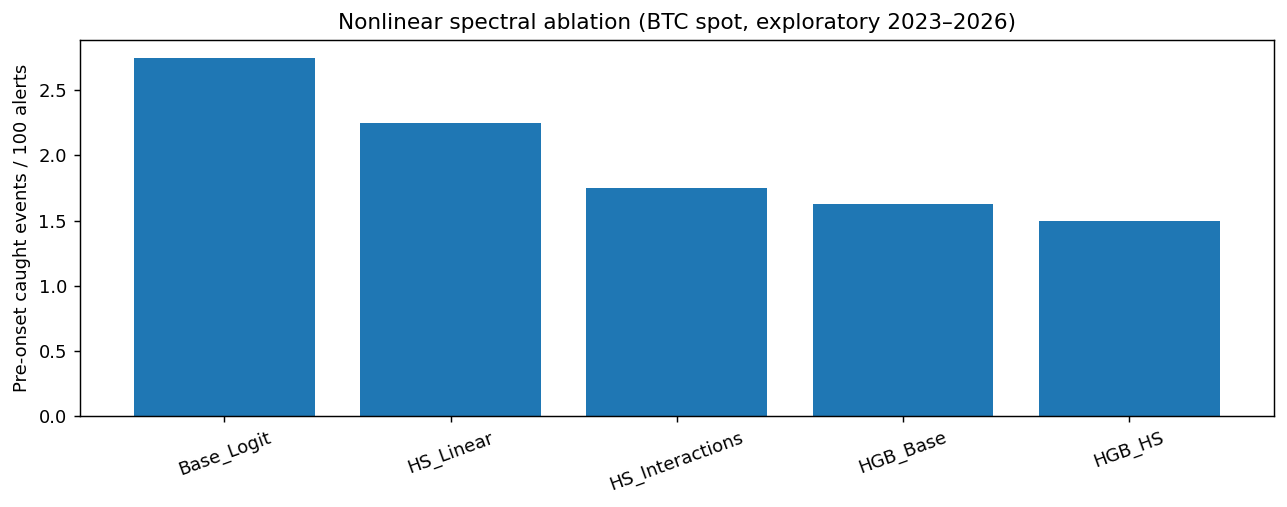

SAVED /content/drive/MyDrive/btc_lead_cost_results_77months_spot/spectral_nonlinear_interactions_v1
Any passing screening result requires a separately fixed, previously unused validation set.


In [7]:
RESULTS.to_csv(OUT/'1_event_level.csv',index=False)
AUC_TABLE.to_csv(OUT/'2_auc.csv',index=False)
PAIR.to_csv(OUT/'3_paired_event_bootstrap_descriptive.csv',index=False)

screens=[]
for base,new in SPEC['comparisons']:
    a=AUC_TABLE[(AUC_TABLE.H==240)&(AUC_TABLE.model==base)].iloc[0]
    b=AUC_TABLE[(AUC_TABLE.H==240)&(AUC_TABLE.model==new)].iloc[0]
    c=RESULTS[(RESULTS.H==240)&(RESULTS.model==base)&(RESULTS.anchor=='breach')].iloc[0]
    d=RESULTS[(RESULTS.H==240)&(RESULTS.model==new)&(RESULTS.anchor=='breach')].iloc[0]
    dau=float(b.auc_pre_within_rv_decile-a.auc_pre_within_rv_decile)
    dy=float(d.pre_catches_per_100_alerts-c.pre_catches_per_100_alerts)
    screens.append({'baseline':base,'candidate':new,
        'base_catches':int(c.pre_catches),'candidate_catches':int(d.pre_catches),
        'baseline_alerts':int(c.alerts),'candidate_alerts':int(d.alerts),
        'd_auc_pre_within_rv_decile':dau,
        'd_pre_catches_per_100_alerts':dy,
        'screen_hurdle_met':bool(dau>=.02 and dy>=.5 and abs(int(d.alerts)-int(c.alerts))<=max(1,int(.01*c.alerts)))})
SCREEN=pd.DataFrame(screens)
SCREEN.to_csv(OUT/'4_screening_readout.csv',index=False)
from IPython.display import display
display(SCREEN)

fig,ax=plt.subplots(figsize=(10,4),dpi=130)
plot=RESULTS[(RESULTS.H==240)&(RESULTS.anchor=='breach')]
ax.bar(plot.model,plot.pre_catches_per_100_alerts)
ax.set_ylabel('Pre-onset caught events / 100 alerts')
ax.set_title('Nonlinear spectral ablation (BTC spot, exploratory 2023–2026)')
ax.tick_params(axis='x',rotation=20)
plt.tight_layout()
fig.savefig(OUT/'fig47_4h_preonset.png')
plt.show()

SUMMARY={
 'status':'exploratory_posthoc',
 'not_holdout_or_prospective':True,
 'spec_sha256':hashlib.sha256((OUT/'47_SPEC.json').read_bytes()).hexdigest(),
 'models':list(MODELS),
 'eval_events_4h':len(EVAL[240]), 'eval_events_24h':len(EVAL[1440]),
 'calibration_alerts':CAL_COUNTS,
 'development_alerts':{k:len(v) for k,v in ALARMS.items()},
 'baseline_M0_reproduction_passed':True,
 'screens':screens,
 'note':'Screening only, negative results must be kept, no new claim of validated predictive improvement.'
}
(OUT/'47_SUMMARY.json').write_text(json.dumps(SUMMARY,indent=2,default=float))
print('SAVED',OUT)
print('Any passing screening result requires a separately fixed, previously unused validation set.')

### Interpretation of the screen

If neither comparison passes, nonlinear use of this `z_hs` provides no convincing incremental value within the model classes I examine. A comparison that passes is an exploratory lead only, because I have inspected the same development years repeatedly.